# Decision Trees - CART, ID3 and C4.5

Lab Assignment 9 - implementing the CART decision tree algorithm from scratch, using it to classify a new sample, and comparing it with ID3 and C4.5 style trees on accuracy, precision, recall and sensitivity.

Dataset: Breast Cancer Wisconsin (bundled with sklearn), 569 samples and 30 numeric features.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

## 1. Load the dataset

In sklearn the target is 0 = malignant and 1 = benign. It is flipped here so that malignant is the positive class (1), which makes precision, recall and sensitivity refer to detecting cancer.

In [2]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = 1 - data.target
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [3]:
print(df.shape)
df['target'].value_counts()

(569, 31)


,count
target,
0,357
1,212


In [4]:
X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(398, 30) (171, 30)


## 2. CART from scratch

CART builds a binary tree. At every node it tries every feature and every threshold (midpoints between sorted unique values) and picks the split that gives the lowest weighted **Gini impurity**:

Gini = 1 - Σ p_i²

The tree keeps splitting until it hits the max depth, the node is pure, or there are too few samples left. Leaves predict the majority class.

In [5]:
def gini(y):
    p = np.bincount(y) / len(y)
    return 1 - np.sum(p ** 2)


def best_split(X, y):
    best_feature, best_threshold = None, None
    best_gini = gini(y)

    for feature in range(X.shape[1]):
        values = np.unique(X[:, feature])
        thresholds = (values[:-1] + values[1:]) / 2

        for t in thresholds:
            left = y[X[:, feature] <= t]
            right = y[X[:, feature] > t]
            g = (len(left) * gini(left) + len(right) * gini(right)) / len(y)

            if g < best_gini:
                best_feature, best_threshold, best_gini = feature, t, g

    return best_feature, best_threshold


def build_tree(X, y, depth=0, max_depth=5, min_samples=5):
    leaf = {'leaf': True, 'value': np.bincount(y).argmax()}

    if depth == max_depth or len(y) < min_samples or len(np.unique(y)) == 1:
        return leaf

    feature, threshold = best_split(X, y)
    if feature is None:
        return leaf

    mask = X[:, feature] <= threshold
    return {
        'leaf': False,
        'feature': feature,
        'threshold': threshold,
        'left': build_tree(X[mask], y[mask], depth + 1, max_depth, min_samples),
        'right': build_tree(X[~mask], y[~mask], depth + 1, max_depth, min_samples)
    }


def predict_one(node, x):
    while not node['leaf']:
        if x[node['feature']] <= node['threshold']:
            node = node['left']
        else:
            node = node['right']
    return node['value']


def predict(tree, X):
    return np.array([predict_one(tree, x) for x in X])

In [6]:
def print_tree(node, names, indent=''):
    if node['leaf']:
        print(indent + 'class:', 'malignant' if node['value'] == 1 else 'benign')
        return
    print(f"{indent}{names[node['feature']]} <= {node['threshold']:.3f}")
    print_tree(node['left'], names, indent + '    ')
    print(f"{indent}{names[node['feature']]} > {node['threshold']:.3f}")
    print_tree(node['right'], names, indent + '    ')

## 3. Building the tree

In [7]:
cart_tree = build_tree(X_train.values, y_train.values, max_depth=4)
print_tree(cart_tree, X.columns)

worst perimeter <= 112.800
    worst concave points <= 0.181
        area error <= 35.435
            worst smoothness <= 0.191
                class: benign
            worst smoothness > 0.191
                class: malignant
        area error > 35.435
            mean radius <= 14.815
                class: benign
            mean radius > 14.815
                class: malignant
    worst concave points > 0.181
        class: malignant
worst perimeter > 112.800
    worst concave points <= 0.140
        mean texture <= 16.780
            class: benign
        mean texture > 16.780
            mean fractal dimension <= 0.063
                class: malignant
            mean fractal dimension > 0.063
                class: benign
    worst concave points > 0.140
        class: malignant


## 4. Classifying a new sample

Taking one sample from the test set that the tree has never seen and following it down the tree.

In [8]:
new_sample = X_test.iloc[0].values
print("Predicted:", 'malignant' if predict_one(cart_tree, new_sample) == 1 else 'benign')
print("Actual   :", 'malignant' if y_test.iloc[0] == 1 else 'benign')

Predicted: benign
Actual   : benign


## 5. ID3 and C4.5 using sklearn

sklearn only has an optimized version of CART, so the other two algorithms are approximated:
- **ID3** - splits using information gain, so criterion='entropy' with no pruning.
- **C4.5** - also entropy based but adds pruning, so criterion='entropy' with min_samples_leaf and cost complexity pruning (ccp_alpha).

sklearn's own Gini tree is also included as a sanity check for the from-scratch CART.

In [9]:
id3 = DecisionTreeClassifier(criterion='entropy', random_state=42)
c45 = DecisionTreeClassifier(criterion='entropy', min_samples_leaf=5, ccp_alpha=0.01, random_state=42)
cart_sklearn = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)

id3.fit(X_train, y_train)
c45.fit(X_train, y_train)
cart_sklearn.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

## 6. Evaluation

Sensitivity is the same thing as recall (TP / (TP + FN)) - the fraction of malignant cases correctly detected. Specificity (TN / (TN + FP)) is added as well since it shows the other side - how many benign cases are correctly identified.

In [10]:
preds = {
    'CART (scratch)': predict(cart_tree, X_test.values),
    'CART (sklearn)': cart_sklearn.predict(X_test),
    'ID3': id3.predict(X_test),
    'C4.5': c45.predict(X_test)
}

results = []
for name, y_pred in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall / Sensitivity': recall_score(y_test, y_pred),
        'Specificity': tn / (tn + fp)
    })

results = pd.DataFrame(results).set_index('Model')
results.round(4)

,Accuracy,Precision,Recall / Sensitivity,Specificity
Model,,,,
CART (scratch),0.8947,0.9423,0.7656,0.9720
CART (sklearn),0.9064,0.9615,0.7812,0.9813
ID3,0.9415,0.9655,0.8750,0.9813
C4.5,0.9298,0.9815,0.8281,0.9907


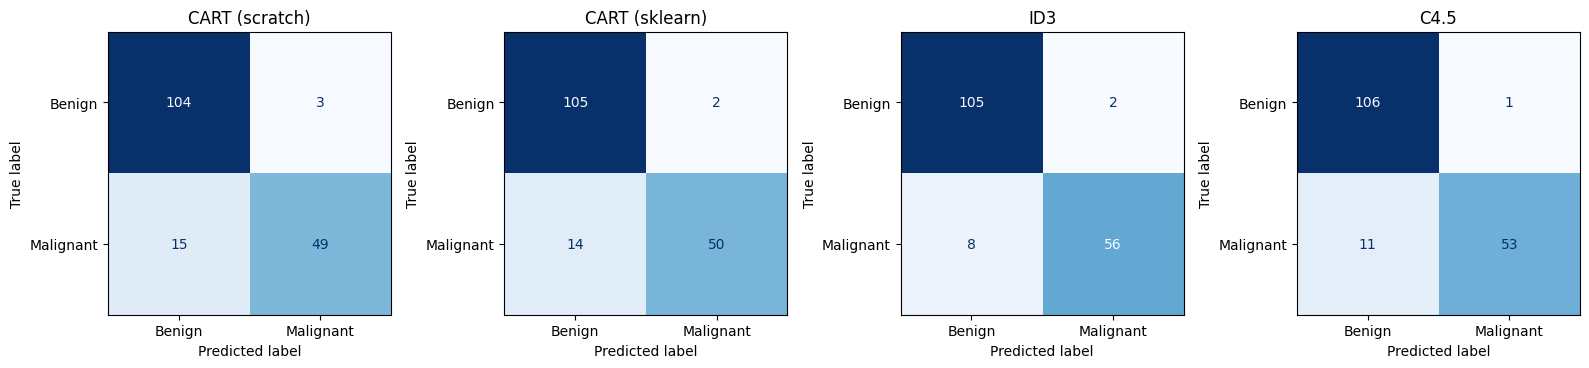

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Malignant']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 7. Comparison

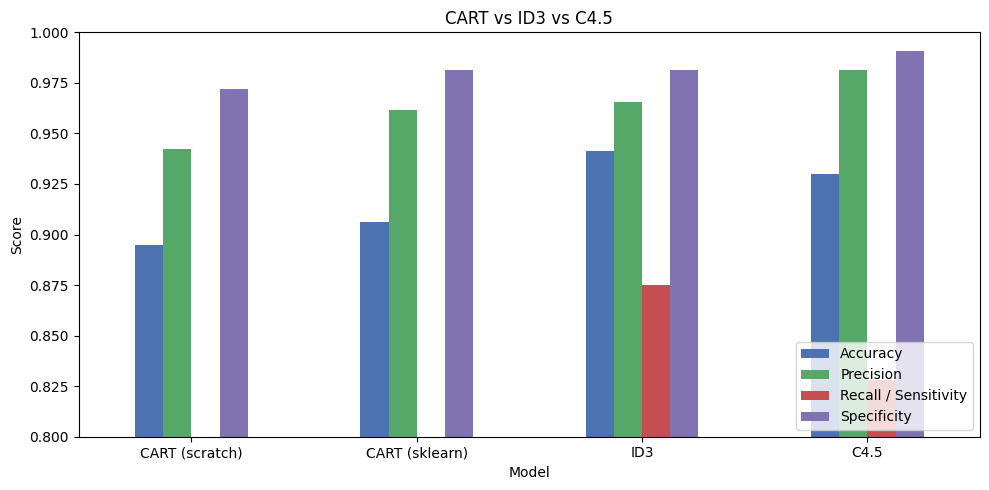

In [12]:
results.plot(kind='bar', figsize=(10, 5), color=['#4c72b0', '#55a868', '#c44e52', '#8172b2'])
plt.ylabel('Score')
plt.title('CART vs ID3 vs C4.5')
plt.ylim(0.8, 1.0)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [13]:
def tree_depth(node):
    if node['leaf']:
        return 0
    return 1 + max(tree_depth(node['left']), tree_depth(node['right']))

def count_leaves(node):
    if node['leaf']:
        return 1
    return count_leaves(node['left']) + count_leaves(node['right'])

sizes = pd.DataFrame({
    'Depth': [tree_depth(cart_tree), cart_sklearn.get_depth(), id3.get_depth(), c45.get_depth()],
    'Leaves': [count_leaves(cart_tree), cart_sklearn.get_n_leaves(), id3.get_n_leaves(), c45.get_n_leaves()]
}, index=preds.keys())
sizes

,Depth,Leaves
CART (scratch),4,9
CART (sklearn),4,9
ID3,8,16
C4.5,6,11


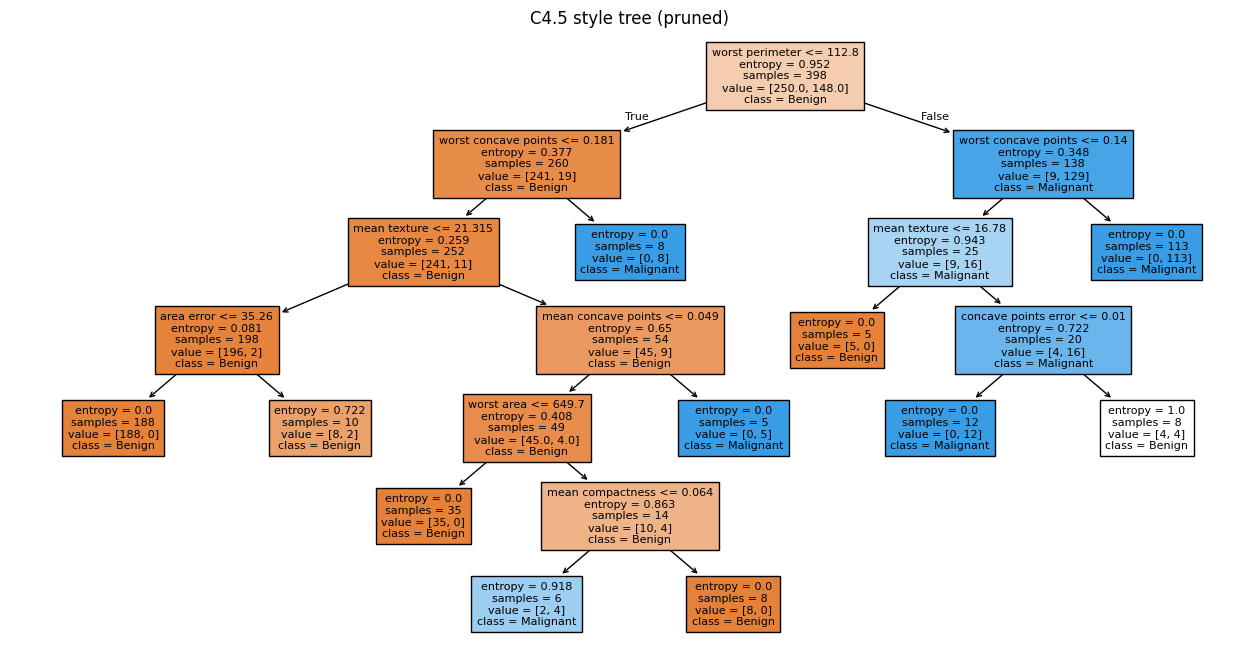

In [14]:
plt.figure(figsize=(16, 8))
plot_tree(c45, feature_names=X.columns, class_names=['Benign', 'Malignant'], filled=True, fontsize=8)
plt.title('C4.5 style tree (pruned)')
plt.show()

## Observations

The from-scratch CART gives the same kind of tree as sklearn's Gini tree - the root splits on one of the "worst" size features (radius, perimeter, area or concave points), and the results on the test set are very close, which shows the implementation works correctly. Small differences can come from ties between splits that have the same Gini value.

The unpruned ID3 tree grows the deepest and has the most leaves since it keeps splitting until every leaf is pure. This fits the training data perfectly but makes it more likely to overfit. The pruned C4.5 style tree is much smaller and generally does as well or better on the test set, which shows the benefit of pruning.

All four trees score in a similar range on this dataset, so the choice between Gini (CART) and entropy (ID3 / C4.5) as the splitting criterion does not make a big difference - in practice the depth and pruning settings matter more. For a cancer dataset the recall / sensitivity column is the most important one, since a missed malignant case is far more costly than a false alarm.

## Conclusion

In this experiment the CART decision tree algorithm was implemented from scratch using Gini impurity and binary splits on continuous features. The tree was built on the Breast Cancer Wisconsin dataset, printed out as a set of if-else rules, and used to classify a new unseen sample. Its results matched sklearn's built-in CART closely, which confirms the implementation is correct.

CART was then compared with ID3 and C4.5 style trees on accuracy, precision, recall (sensitivity) and specificity. All of them performed similarly, with the main difference being tree size - the unpruned ID3 tree was the most complex, while the depth limited CART and the pruned C4.5 trees were simpler and easier to interpret without losing much performance. Controlling the tree size through max depth or pruning is the key to getting a decision tree that generalizes well.